## Proyecto Logistica

In [53]:
#Instalamos la libreria osmnx la cual nos permite descargar mapas y convertirlos en grafos
%pip install osmnx

Note: you may need to restart the kernel to use updated packages.


In [54]:
#Instalamos folium la cual es una libreria que permite crear mapas interactivos en web con python
%pip install folium

Note: you may need to restart the kernel to use updated packages.


### 1.1 Descargar el mapa de cartagena debemos acceder a Openstreetmap y ajustar el mapa a nuestro gusto

8718 nodos
32076 aristas


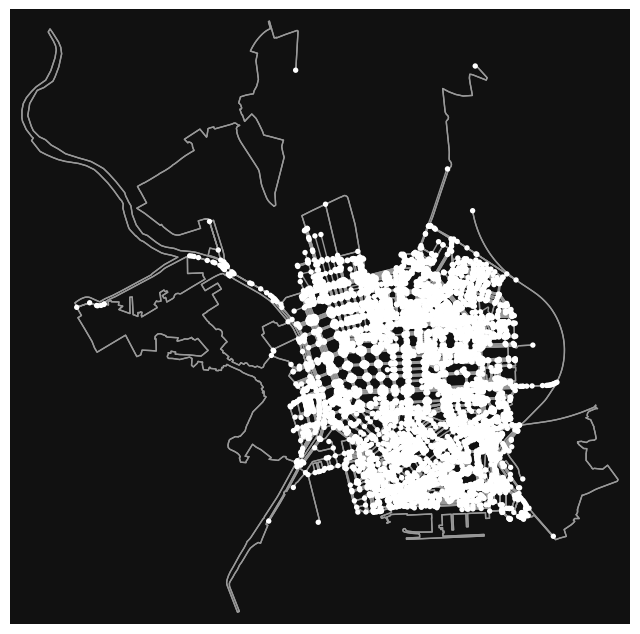

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [55]:
import osmnx as ox

# Cargar el mapa descargado
G = ox.graph_from_xml("/kaggle/input/datasets/rubendelvalle/mapa-crt2/map2.osm", simplify=True)
nodes, edges = ox.graph_to_gdfs(G)
print(len(G.nodes), "nodos") #Numero de nodos que se crean en base al mapa
print(len(G.edges), "aristas") #Numero de aristas que se crean en base al mapa
ox.plot_graph(G)

### Como vamos a querer tres mapas de reparto, es necesario establecer por que vias puede acceder cada vehiculo.

In [57]:
#Los nodos se puede ver reflejado en un dataset
nodes
# osmid -> Identificador único de cada nodo
# y -> Latitud del nodo en grados
# x -> Longitud en grados
# highway -> Etiqueta de OSM que permite saber el tipo de elemento viario del nodo
# railway -> Igual que el anterior pero para elementos ferroviarios
# geometry -> El nodo en formato geoespacial (longitud, latitud)

,y,x,highway,railway,geometry
osmid,,,,,
4760010782,37.604880,-0.987920,crossing,NaN,POINT (-0.98792 37.60488)
4760010783,37.604972,-0.988457,NaN,NaN,POINT (-0.98846 37.60497)
4760010784,37.605255,-0.989428,crossing,NaN,POINT (-0.98943 37.60526)
2329935922,37.602579,-0.980900,NaN,NaN,POINT (-0.9809 37.60258)
3474849902,37.606980,-0.977477,NaN,NaN,POINT (-0.97748 37.60698)
...,...,...,...,...,...
4983357365,37.600208,-0.988050,NaN,NaN,POINT (-0.98805 37.60021)
4983357367,37.600249,-0.987676,NaN,NaN,POINT (-0.98768 37.60025)
4983357368,37.600251,-0.987578,NaN,NaN,POINT (-0.98758 37.60025)


In [58]:
edges
# osmid -> identificador de la vía
# highway -> tipo de vía.
# name -> nombre de la calle.
# oneway -> True si solo se puede circular en un sentido. El grafo respeta el sentido de u a v.
# reversed -> True si la arista está dibujada en sentido contrario al de la vía original en OSM.
# length -> longitud del tramo en metros.
# area -> etiqueta de OSM que indica si la vía es un área (por ejemplo una plaza peatonal).
# geometry -> la forma del tramo como línea (LINESTRING), con sus coordenadas (longitud, latitud).
# maxspeed -> velocidad máxima permitida.
# bridge -> indica si el tramo es un puente.
# landuse -> uso del suelo asociado.
# lanes -> número de carriles.
# width -> anchura de la vía, si consta

osmid        highway  \
u          v           key                                           
4760010782 12059388540 0                   39894862  living_street   
                       1                 1455806762     pedestrian   
           10074925769 0                 1302028157        footway   
                       1                 1455806762     pedestrian   
           4760010783  0    [1100833441, 368144346]        footway   
...                                             ...            ...   
3817471943 3817464980  1                  378332068            NaN   
                       2                 1444006396            NaN   
           3074184014  0                  378332068            NaN   
                       1                  378332144            NaN   
                       2                 1444006397        footway   

                                           name  oneway       reversed  \
u          v           key                                               
4760010782 12059388540 0       Plaza Juan XXIII    True          False   
                       1       Plaza Juan XXIII   False           True   
           10074925769 0                    NaN   False           True   
                       1       Plaza Juan XXIII   False          False   
           4760010783  0                    NaN   False  [False, True]   
...                                         ...     ...            ...   
3817471943 3817464980  1                    NaN   False           True   
                       2    Parque de San Ginés   False          False   
           3074184014  0                    NaN   False          False   
                       1                    NaN   False          False   
                       2                    NaN   False          False   

                               length area  \
u          v           key                   
4760010782 12059388540 0     6.853697  NaN   
                       1     6.853697  yes   
           10074925769 0     3.749283  NaN   
                       1     3.749283  yes   
           4760010783  0    51.358411  NaN   
...                               ...  ...   
3817471943 3817464980  1     2.798992  NaN   
                       2     2.798992  NaN   
           3074184014  0     9.374969  NaN   
                       1     9.374969  NaN   
                       2     9.374969  NaN   

                                                                     geometry  \
u          v           key                                                      
4760010782 12059388540 0    LINESTRING (-0.98792 37.60488, -0.98787 37.60484)   
                       1    LINESTRING (-0.98792 37.60488, -0.98787 37.60484)   
           10074925769 0     LINESTRING (-0.98792 37.60488, -0.9879 37.60491)   
                       1     LINESTRING (-0.98792 37.60488, -0.9879 37.60491)   
           4760010783  0    LINESTRING (-0.98792 37.60488, -0.98797 37.604...   
...                                                                       ...   
3817471943 3817464980  1    LINESTRING (-0.97778 37.61134, -0.97778 37.61132)   
                       2    LINESTRING (-0.97778 37.61134, -0.97778 37.61132)   
           3074184014  0    LINESTRING (-0.97778 37.61134, -0.97769 37.61131)   
                       1    LINESTRING (-0.97778 37.61134, -0.97769 37.61131)   
                       2    LINESTRING (-0.97778 37.61134, -0.97769 37.61131)   

                           maxspeed bridge        landuse lanes width access  \
u          v           key                                                     
4760010782 12059388540 0        NaN    NaN            NaN   NaN   NaN    NaN   
                       1        NaN    NaN            NaN   NaN   NaN    NaN   
           10074925769 0        NaN    NaN            NaN   NaN   NaN    NaN   
                       1        NaN    NaN            NaN   NaN   NaN    NaN   
           4760010783  0        NaN    

## 1.2 Definir los tipos de grafos para cada tipo de vehiculo

In [106]:
def filtrar_grafo(G, permitidos):
    aristas = []
    for u, v, k, data in G.edges(keys=True, data=True):
        #Obtenemos el tipo de via de la arista
        hw = data.get("highway")
        #Es posible que un mismo tramo sea clasificado en diferentes tipos
        hw = hw if isinstance(hw, list) else [hw] #Si no es una lista se la envuelve en una
        #Se comprueba que ese tramo entra dentro de los permitidos.
        if any(h in permitidos for h in hw):
            aristas.append((u, v, k))
    return G.edge_subgraph(aristas).copy()
#Vehiculo: Vias unicamente que sean carreteras
vias_coche = {"motorway", "trunk", "primary", "secondary", "tertiary", "unclassified",
              "residential", "living_street", "service",
              "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link"}

# Bici: Tanto carreteras como carriles bici
vias_bici = (vias_coche - {"motorway", "motorway_link", "trunk", "trunk_link", "primary_link"}) \
            | {"cycleway", "path", "track", "pedestrian"}

# Pie: Sendas peatonales, aceras, parques,...
vias_pie  =  {"footway", "pedestrian", "steps", "path", "corridor",
            "residential", "living_street", "service", "unclassified"}

grafos = {
    "coche": filtrar_grafo(G, vias_coche),
    "bici":  filtrar_grafo(G, vias_bici),
    "pie":   filtrar_grafo(G, vias_pie),
}

## 1.3 Seleccionar unos 40 nodos los cuales usaremos como referencias o tiendas a las que acudir
### Para que esten balanceados en el mapa los seleccionaremos aleatoriamente

In [100]:
import random
import pandas as pd

#Para seleccionar nodos comunes a los tres mapas y dentro de la componente conexa principal de cada uno.
def largest_scc(G):
    return max(nx.strongly_connected_components(G), key=len)

#Creamos una lista con los nodos comunes y accesibles
common = (largest_scc(grafos['coche']) & largest_scc(grafos['bici']) & largest_scc(grafos['pie']))
print("Nodos comunes:", len(common))

N_NODOS = 40 # cuántos nodos usaremos como referencia
SEMILLA = 42 

#Elegir N_NODOS posiciones al azar con randint
random.seed(SEMILLA)
posiciones = set() #Hacemos un conjunto para evitar duplicados
#Generamos 40 posiciones aleatorias
while len(posiciones) < N_NODOS:
    posiciones.add(random.randint(0, len(list(common)) - 1))   # randint incluye ambos extremos   
#Guardamos los nodos de esas posiciones
mis_nodos = [list(common)[p] for p in sorted(posiciones)] #Listar los nodos seleccionados

#Recoger sus coordenadas en una tabla y guardarla
seleccion = pd.DataFrame({
    "id": range(1, N_NODOS + 1),
    "nodo": mis_nodos,                                  
    "lat": [G.nodes[n]["y"] for n in mis_nodos],       
    "lon": [G.nodes[n]["x"] for n in mis_nodos]
})
print(seleccion.head())



Nodos comunes: 1719
   id        nodo        lat       lon
0   1  1784389720  37.599311 -0.988621
1   2  2782036262  37.615172 -0.980658
2   3  2782036277  37.615336 -0.980466
3   4   626073947  37.599608 -0.981662
4   5  3533750640  37.612074 -0.984236


## 1.4 Hacer mapa interactivo

In [101]:
import folium
#Seleccionamos el centro de nuestro mapa para que Oms pueda ubicarlo correctamente
centro = [nodes["y"].mean(), nodes["x"].mean()]
def crear_mapa(G, color, centro):
    #Creamos el mapa interactivo
    m = folium.Map(location=centro, zoom_start=14, tiles="OpenStreetMap")
    #Intriducimos en el mapa su grafo correspondiente
    edges_modo = ox.graph_to_gdfs(G, nodes=False)[["geometry"]]
    folium.GeoJson(
        edges_modo,
        style_function=lambda f: {"color": color, "weight": 1.5}
    ).add_to(m)
    return m

# Añadimos los 40 nodos seleccionados anteriormente
def añadir_paradas(mapa):
    for _, fila in seleccion.iterrows():
            folium.CircleMarker([fila["lat"], fila["lon"]], radius=4, color="#444",
                            fill=True, fill_opacity=0.8,
                            tooltip=f"Parada {int(fila['id'])}").add_to(mapa)

m_vehiculo = crear_mapa(grafos['coche'], "#888888", centro) #Color gris
m_bici     = crear_mapa(grafos["bici"],  "#2e8b57", centro) #Color verde
m_pie      = crear_mapa(grafos["pie"],   "#e67e22", centro) #Color naranja
añadir_paradas(m_vehiculo)
añadir_paradas(m_bici)
añadir_paradas(m_pie)


In [102]:
m_vehiculo

In [103]:
m_bici

In [104]:
m_pie

## 1.5 Calculo matriz de distancias entre nodos

In [107]:
# Matriz de distancias
import osmnx as ox
import networkx as nx
import numpy as np
import pandas as pd

#Creo una lista con los nodos seleccionados
lista_nodos_comun = seleccion["nodo"].tolist()

#Creo una matriz vacia, la cual rellenaremos con las distancias
n = len(lista_nodos_comun)

#Calculo la matriz de distancias en función del tipo de vehiculo
def calculo_d(G):
    #Creo matriz con infinitos
    matriz = np.full((n, n), np.inf)
    for i, origen in enumerate(lista_nodos_comun):
        #Calculo todas las distancias desde el nodo de origen a todos los demas.
        distancias = nx.single_source_dijkstra_path_length(G, origen, weight="length")
        #Obtengo la distancia desde el nodo objetivo al de origen
        for j, destino in enumerate(lista_nodos_comun):
            matriz[i, j] = distancias.get(destino, np.inf)
    return matriz



d_vehiculo = calculo_d(grafos["coche"])
d_bici = calculo_d(grafos["bici"])
d_pie = calculo_d(grafos["pie"])
print(d_vehiculo)

[[   0.         3577.23725278 3605.07584468 ... 1418.14371303
  2350.72566975 3223.18495657]
 [3480.40816962    0.           33.0289538  ... 2499.01469926
  2038.04081211 1946.83390262]
 [3495.65002538   46.35257011    0.         ... 2514.25655502
  2053.28266787 1962.07575838]
 ...
 [1293.46517357 2509.00540292 2536.84399482 ...    0.
  1282.49381989 2154.95310671]
 [2348.79240373 1994.2252995  2022.0638914  ... 1405.23909333
     0.         1369.0949071 ]
 [3174.9486367  1841.22723688 1869.06582878 ... 2231.3953263
  1732.58127919    0.        ]]
